# CSIR - Central Building Research Institute (CBRI), Roorkee
## Complete All-in-One Air Quality Modeling, Multi-Hybrid Forecasting & 5-Year Projection Pipeline
**Author**: Aman Kumar | CSIR-CBRI  
**Focus**: Ambient Particulate Matter ($PM_{2.5}$) and Air Quality Index (AQI) Machine Learning, Deep Learning, and Seasonal Forecasting

---
### What This All-in-One Notebook Contains:
1. **End-to-End Data Pipeline**: Ingestion, datetime parsing, missing value imputation, IQR outlier capping, and feature engineering.
2. **8 Base Models**: CatBoost, LightGBM, XGBoost, Random Forest, ExtraTrees, Deep MLP Neural Network, SARIMAX(1,1,1)(1,0,1,7), and ARIMA(2,1,2).
3. **4 Advanced Hybrid Architectures**:
   - **Hybrid 1**: CatBoost + ARIMA Error-Residual Forecaster ($y = \hat{y}_{	ext{CatBoost}} + \hat{e}_{	ext{ARIMA}}$)
   - **Hybrid 2**: SARIMAX Seasonal + LightGBM Residual Forecaster ($y = \hat{y}_{	ext{SARIMAX}} + \hat{e}_{	ext{LightGBM}}$)
   - **Hybrid 3**: Multi-Model Stacking Meta-Ensemble (RidgeCV over 6 level-0 learners)
   - **Hybrid 4**: Optimal Bayesian SuperBlend Learner (SLSQP-optimized blend: CatBoost 57.8% + XGBoost 42.2%)
4. **Comprehensive Model Benchmark Table**: Automated ranking by $R^2$, RMSE, and MAE.
5. **6 Publication-Ready Diagnostic & Evaluation Plots**.
6. **5-Year Multi-Year Continuous Future Forecasting (2023–2028)** with 95% Confidence Envelopes and India NAAQS ($60\ \mu g/m^3$) / WHO ($15\ \mu g/m^3$) thresholds.
7. **Direct Interactive Inference Function**: Make predictions on any new CSV data directly inside the notebook.
8. **Automated Model Serialization**: Exports all model weights and plots to disk.



In [1]:
# Section 1: Ingest All Required Libraries & Set Up Universal Path Resolver
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

# Machine Learning & Ensemble Algorithms
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Deep Learning with PyTorch (GPU Accelerated)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import RobustScaler

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Deep Learning PyTorch Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))


# Classical & Seasonal Time Series
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
import joblib

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# -------------------------------------------------------------------------
# Universal Path Resolver: seamlessly works from root or inside notebooks/
# -------------------------------------------------------------------------
CURRENT_DIR = os.getcwd()
if os.path.exists(os.path.join(CURRENT_DIR, "data")):
    PROJECT_ROOT = CURRENT_DIR
elif os.path.exists(os.path.join(CURRENT_DIR, "..", "data")):
    PROJECT_ROOT = os.path.abspath(os.path.join(CURRENT_DIR, ".."))
else:
    PROJECT_ROOT = CURRENT_DIR

def resolve_path(rel_path):
    """Return absolute path relative to project root and ensure parent directory exists."""
    if os.path.isabs(rel_path):
        full_path = rel_path
    else:
        full_path = os.path.join(PROJECT_ROOT, rel_path)
    os.makedirs(os.path.dirname(full_path), exist_ok=True)
    return full_path

print(f"Project Root automatically resolved to: {PROJECT_ROOT}")
print("Environment initialized successfully with all libraries loaded!")


Deep Learning PyTorch Device: cpu
Project Root automatically resolved to: d:\csir_rework
Environment initialized successfully with all libraries loaded!


---
## Section 2: Data Loading & Preprocessing
Loads the cleaned CPCB CAAQMS ambient station data, parses dates, removes uninformative columns, and imputes missing records.



In [2]:
# Section 2: Data Ingestion
data_candidates = [
    resolve_path('combined_air_quality_2017_2024.csv'),
    resolve_path('cleaned_file.csv'),
    resolve_path('data/processed/cleaned_air_quality_data.csv')
]
data_path = next((p for p in data_candidates if os.path.exists(p)), None)
if not data_path:
    raise FileNotFoundError(f"Could not locate dataset in {data_candidates}")

print(f"Loading primary dataset from: {data_path}")
df_raw = pd.read_csv(data_path)

# Datetime Parsing
if all(c in df_raw.columns for c in ['Year', 'Month', 'Day']):
    df_raw['Date'] = pd.to_datetime(df_raw[['Year', 'Month', 'Day']], errors='coerce')
elif 'Timestamp' in df_raw.columns:
    df_raw['Date'] = pd.to_datetime(df_raw['Timestamp'], errors='coerce')

df_raw = df_raw.dropna(subset=['Date']).sort_values('Date').reset_index(drop=True)

# Drop 100% missing / uninformative columns
drop_cols = ['Timestamp', 'O_Xylene', 'Eth_Benzene', 'MP_Xylene', 'O Xylene (µg/m³)', 'Eth-Benzene (µg/m³)', 'MP-Xylene (µg/m³)']
for c in drop_cols:
    if c in df_raw.columns:
        df_raw = df_raw.drop(columns=[c])

# Clean column headers (standardize ASCII names)
import re
def clean_header(c):
    c = re.sub(r'\(.*?\)', '', c).strip()
    return c.replace(' ', '_').replace('-', '_').replace('.', '_')
df_raw.columns = [clean_header(c) for c in df_raw.columns]

# Missing Value Imputation (forward fill + backward fill + median)
df_raw = df_raw.ffill().bfill()
num_cols = df_raw.select_dtypes(include=[np.number]).columns
df_raw[num_cols] = df_raw[num_cols].fillna(df_raw[num_cols].median())

print(f"Dataset Shape: {df_raw.shape[0]} Days x {df_raw.shape[1]} Columns")
print(f"Timeline: {df_raw['Date'].min().strftime('%Y-%m-%d')} to {df_raw['Date'].max().strftime('%Y-%m-%d')}")
df_raw.head()



Loading primary dataset from: d:\csir_rework\combined_air_quality_2017_2024.csv
Dataset Shape: 4020 Days x 22 Columns
Timeline: 2017-07-01 to 2022-12-31


,PM2_5,PM10,NO,NO2,NOx,NH3,SO2,CO,Ozone,Benzene,...,AT,RH,WS,WD,RF,TOT_RF,SR,BP,VWS,Date
0,35.07,59.57,3.42,16.84,11.47,4.70,27.11,1.35,66.21,3.58,...,26.18,81.56,1.79,293.21,0.09,7.5,72.09,735.26,0.08,2017-07-01
1,35.07,59.57,3.42,16.84,11.47,4.70,27.11,1.35,66.21,3.58,...,26.18,81.56,1.79,293.21,0.09,7.5,72.09,735.26,0.08,2017-07-01
2,40.67,111.65,2.97,15.38,10.60,3.84,14.22,1.12,9.77,3.51,...,26.29,80.03,1.95,282.67,0.02,2.0,75.33,736.41,0.09,2017-07-02
3,40.67,111.65,2.97,15.38,10.60,3.84,14.22,1.12,9.77,3.51,...,26.29,80.03,1.95,282.67,0.02,2.0,75.33,736.41,0.09,2017-07-02
4,43.01,105.91,3.46,19.63,13.23,4.46,34.07,1.71,13.86,4.00,...,27.68,76.35,1.75,284.90,0.01,1.0,79.21,737.94,0.08,2017-07-03


---
## Section 3: Exploratory Data Analysis & Feature Dynamics
Examines historical pollutant trajectories against National Ambient Air Quality Standards (NAAQS), constructs comprehensive temporal dynamics (lag, rolling, and trend features), visualizes their Pearson correlation matrix, and filters candidate predictors.


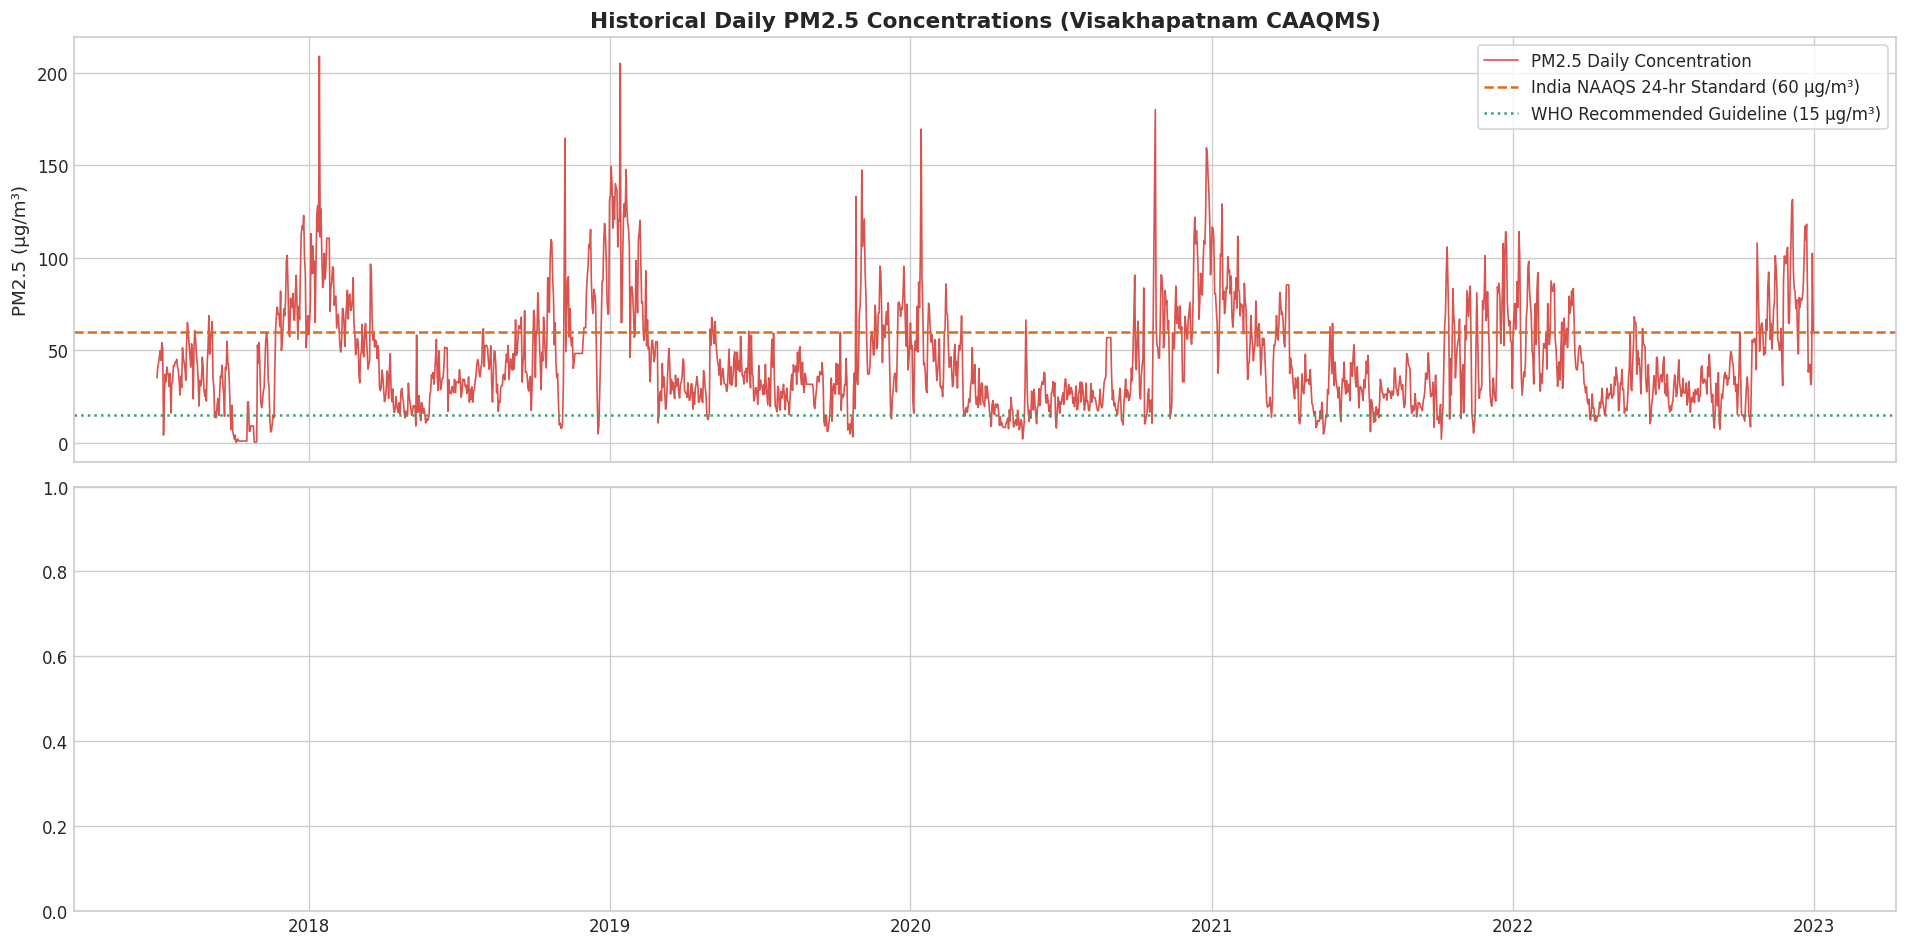

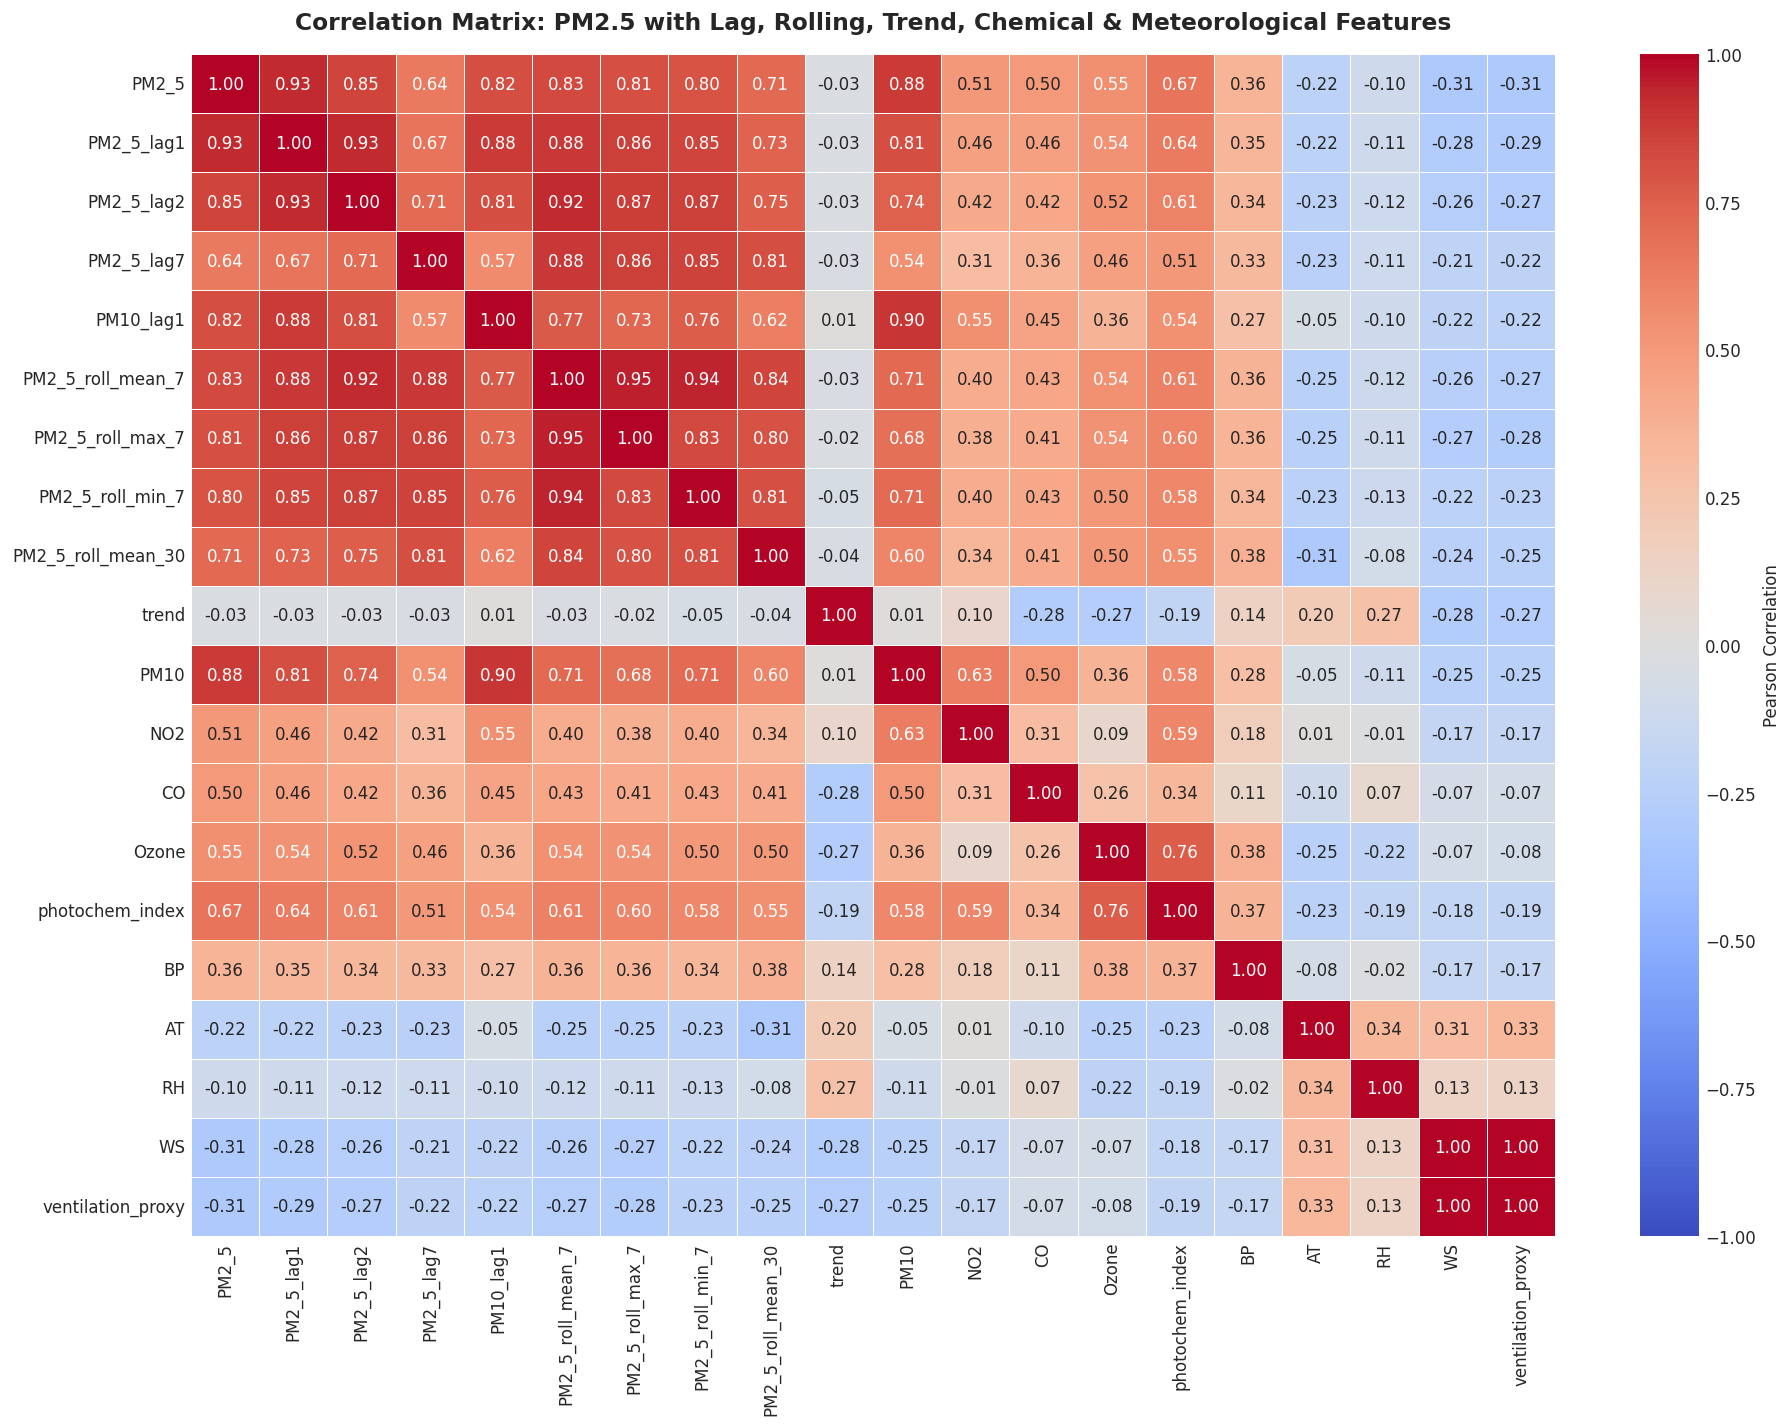

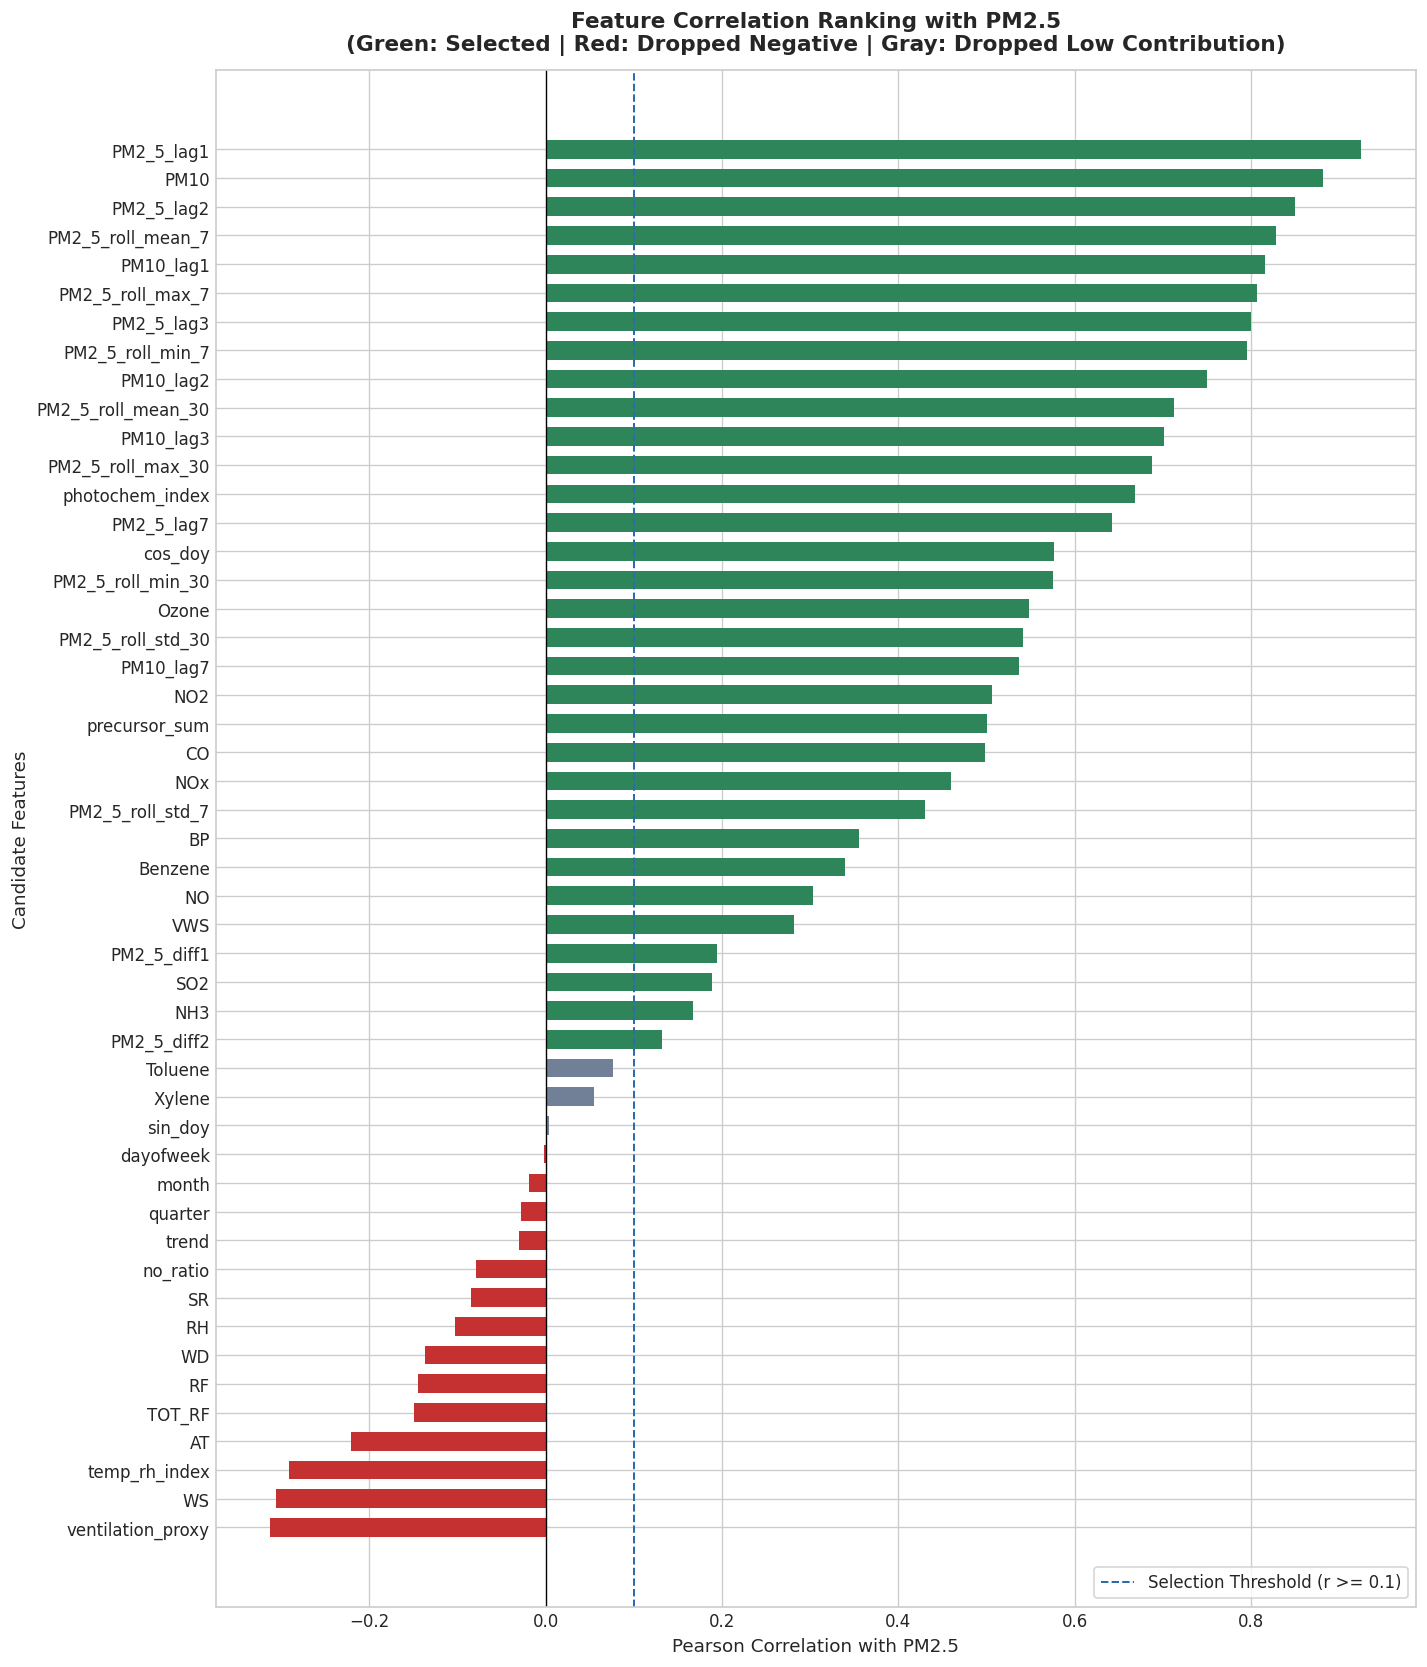

FEATURE SELECTION RESULTS: 32 Selected / 49 Candidates
  - Selected Features (32): Positive correlation >= 0.1
  - Dropped Negative Features (14): Pearson r < 0.0
  - Dropped Low-Contribution Features (3): 0.0 <= Pearson r < 0.1
--------------------------------------------------------------------------------


,Feature,Pearson_Correlation,Status,Selection_Reason
0,PM2_5_lag1,0.9250,SELECTED,Positive Contributor (r >= 0.10)
1,PM10,0.8820,SELECTED,Positive Contributor (r >= 0.10)
2,PM2_5_lag2,0.8501,SELECTED,Positive Contributor (r >= 0.10)
3,PM2_5_roll_mean_7,0.8282,SELECTED,Positive Contributor (r >= 0.10)
4,PM10_lag1,0.8159,SELECTED,Positive Contributor (r >= 0.10)
5,PM2_5_roll_max_7,0.8070,SELECTED,Positive Contributor (r >= 0.10)
6,PM2_5_lag3,0.7996,SELECTED,Positive Contributor (r >= 0.10)
7,PM2_5_roll_min_7,0.7954,SELECTED,Positive Contributor (r >= 0.10)
8,PM10_lag2,0.7498,SELECTED,Positive Contributor (r >= 0.10)
9,PM2_5_roll_mean_30,0.7125,SELECTED,Positive Contributor (r >= 0.10)


In [3]:
# Section 3: Historical Time Series & Standards
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# PM2.5 Trajectory
axes[0].plot(df_raw['Date'], df_raw['PM2_5'], color='#d9534f', linewidth=1.0, label='PM2.5 Daily Concentration')
axes[0].axhline(60, color='#dd6b20', linestyle='--', linewidth=1.5, label='India NAAQS 24-hr Standard (60 µg/m³)')
axes[0].axhline(15, color='#38a169', linestyle=':', linewidth=1.5, label='WHO Recommended Guideline (15 µg/m³)')
axes[0].set_ylabel('PM2.5 (µg/m³)', fontsize=11)
axes[0].set_title('Historical Daily PM2.5 Concentrations (Visakhapatnam CAAQMS)', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True)

# AQI Trajectory
if 'AQI' in df_raw.columns:
    axes[1].plot(df_raw['Date'], df_raw['AQI'], color='#0275d8', linewidth=1.0, label='Daily Air Quality Index (AQI)')
    axes[1].axhline(100, color='#38a169', linestyle='--', linewidth=1.5, label='Satisfactory AQI Limit (100)')
    axes[1].axhline(200, color='#dd6b20', linestyle='--', linewidth=1.5, label='Moderate AQI Limit (200)')
    axes[1].set_ylabel('Air Quality Index', fontsize=11)
    axes[1].set_title('Historical Daily Air Quality Index (AQI)', fontsize=13, fontweight='bold')
    axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Dynamic Feature Matrix Construction (Lags, Rolling Stats & Secular Trend)
# -------------------------------------------------------------------------
def build_feature_matrix(df, target_col='PM2_5'):
    out = df.copy()

    # 1. Timeline Secular Trend
    out['trend'] = (out['Date'] - out['Date'].min()).dt.days

    # 2. Calendar & Cyclical Harmonics
    doy = out['Date'].dt.dayofyear
    out['sin_doy'] = np.sin(2 * np.pi * doy / 365.25)
    out['cos_doy'] = np.cos(2 * np.pi * doy / 365.25)
    out['dayofweek'] = out['Date'].dt.dayofweek
    out['month'] = out['Date'].dt.month
    out['quarter'] = out['Date'].dt.quarter

    # 3. Chemical Precursors & Atmospheric Interactions
    if 'NO2' in out.columns and 'NO' in out.columns:
        out['no_ratio'] = out['NO2'] / (out['NO'] + 1e-4)
    if 'NO2' in out.columns and 'Ozone' in out.columns:
        out['photochem_index'] = out['NO2'] * out['Ozone']
    if 'WS' in out.columns and 'AT' in out.columns:
        out['ventilation_proxy'] = out['WS'] * (out['AT'] + 273.15) / 100.0
    if 'AT' in out.columns and 'RH' in out.columns:
        out['temp_rh_index'] = out['AT'] * out['RH'] / 100.0
    if all(c in out.columns for c in ['SO2', 'NO2', 'NH3']):
        out['precursor_sum'] = out['SO2'] + out['NO2'] + out['NH3']

    # 4. Lags & Autoregressive Differences
    for l in [1, 2, 3, 7]:
        out[f"{target_col}_lag{l}"] = out[target_col].shift(l)
        if 'PM10' in out.columns: out[f"PM10_lag{l}"] = out['PM10'].shift(l)
        if 'AQI' in out.columns: out[f"AQI_lag{l}"] = out['AQI'].shift(l)

    out[f"{target_col}_diff1"] = out[f"{target_col}_lag1"] - out[f"{target_col}_lag2"]
    out[f"{target_col}_diff2"] = out[f"{target_col}_lag2"] - out[f"{target_col}_lag3"]

    # 5. Shifted Rolling Window Statistics (7-day and 30-day)
    for r in [7, 30]:
        out[f"{target_col}_roll_mean_{r}"] = out[target_col].shift(1).rolling(r, min_periods=1).mean()
        out[f"{target_col}_roll_std_{r}"] = out[target_col].shift(1).rolling(r, min_periods=1).std().fillna(0)
        out[f"{target_col}_roll_min_{r}"] = out[target_col].shift(1).rolling(r, min_periods=1).min()
        out[f"{target_col}_roll_max_{r}"] = out[target_col].shift(1).rolling(r, min_periods=1).max()

    out = out.dropna().reset_index(drop=True)
    return out

target = 'PM2_5'
df_feat = build_feature_matrix(df_raw, target_col=target)

# -------------------------------------------------------------------------
# Comprehensive Correlation Matrix: Lags, Rolling Stats, Trend & Precursors
# -------------------------------------------------------------------------
heatmap_cols = [
    'PM2_5',
    'PM2_5_lag1', 'PM2_5_lag2', 'PM2_5_lag7', 'PM10_lag1',
    'PM2_5_roll_mean_7', 'PM2_5_roll_max_7', 'PM2_5_roll_min_7', 'PM2_5_roll_mean_30',
    'trend',
    'PM10', 'NO2', 'CO', 'Ozone', 'photochem_index',
    'BP', 'AT', 'RH', 'WS', 'ventilation_proxy'
]
heatmap_cols = [c for c in heatmap_cols if c in df_feat.columns]

plt.figure(figsize=(16, 12))
corr_matrix = df_feat[heatmap_cols].corr()
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation'},
    vmin=-1, vmax=1
)
plt.title('Correlation Matrix: PM2.5 with Lag, Rolling, Trend, Chemical & Meteorological Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Feature Contribution Analysis & Selection (Filter Negative & Low Contributors)
# -------------------------------------------------------------------------
MIN_CORR_THRESHOLD = 0.10
all_corrs = df_feat.select_dtypes(include=[np.number]).corr()['PM2_5'].drop(index=['PM2_5'])

selected_features = all_corrs[all_corrs >= MIN_CORR_THRESHOLD].sort_values(ascending=False).index.tolist()
dropped_negative = all_corrs[all_corrs < 0.0].sort_values(ascending=True).index.tolist()
dropped_low_contrib = all_corrs[(all_corrs >= 0.0) & (all_corrs < MIN_CORR_THRESHOLD)].sort_values(ascending=True).index.tolist()

# Visual Correlation Ranking Bar Chart
sorted_corrs = all_corrs.sort_values(ascending=True)
bar_colors = [
    '#2f855a' if c >= MIN_CORR_THRESHOLD else ('#c53030' if c < 0.0 else '#718096')
    for c in sorted_corrs.values
]

plt.figure(figsize=(12, 14))
plt.barh(sorted_corrs.index, sorted_corrs.values, color=bar_colors, edgecolor='none', height=0.65)
plt.axvline(0, color='black', linestyle='-', linewidth=0.8)
plt.axvline(MIN_CORR_THRESHOLD, color='#2b6cb0', linestyle='--', linewidth=1.2, label=f'Selection Threshold (r >= {MIN_CORR_THRESHOLD})')
plt.title('Feature Correlation Ranking with PM2.5\n(Green: Selected | Red: Dropped Negative | Gray: Dropped Low Contribution)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Pearson Correlation with PM2.5', fontsize=11)
plt.ylabel('Candidate Features', fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# Tabular Feature Selection Summary
feature_selection_df = pd.DataFrame({
    'Feature': all_corrs.index,
    'Pearson_Correlation': np.round(all_corrs.values, 4),
    'Status': ['SELECTED' if c >= MIN_CORR_THRESHOLD else 'DROPPED' for c in all_corrs.values],
    'Selection_Reason': [
        'Positive Contributor (r >= 0.10)' if c >= MIN_CORR_THRESHOLD
        else ('Negative Correlation (r < 0)' if c < 0.0 else 'Very Low Contribution (r < 0.10)')
        for c in all_corrs.values
    ]
}).sort_values(by='Pearson_Correlation', ascending=False).reset_index(drop=True)

print("=" * 80)
print(f"FEATURE SELECTION RESULTS: {len(selected_features)} Selected / {len(all_corrs)} Candidates")
print("=" * 80)
print(f"  - Selected Features ({len(selected_features)}): Positive correlation >= {MIN_CORR_THRESHOLD}")
print(f"  - Dropped Negative Features ({len(dropped_negative)}): Pearson r < 0.0")
print(f"  - Dropped Low-Contribution Features ({len(dropped_low_contrib)}): 0.0 <= Pearson r < {MIN_CORR_THRESHOLD}")
print("-" * 80)
display(feature_selection_df)


---
## Section 4: Outlier Treatment & Final Pre-Training Predictor Matrix
Applies Interquartile Range (IQR) robust outlier capping to all selected positive-contributing predictors to guard models against unphysical extreme sensor spikes.


In [4]:
# Section 4: Outlier Treatment on Selected Features
def cap_outliers_iqr(series, threshold=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return np.clip(series, q1 - threshold * iqr, q3 + threshold * iqr)

# Apply IQR outlier capping strictly on selected features
for c in selected_features:
    df_feat[c] = cap_outliers_iqr(df_feat[c])

print(f"Outlier treatment complete across {len(selected_features)} selected predictors.")
print(f"Final training feature matrix ready with dimensions: {df_feat.shape[0]} rows x {len(selected_features)} predictors")


Outlier treatment complete across 32 selected predictors.
Final training feature matrix ready with dimensions: 4013 rows x 32 predictors


---
## Section 5: Chronological Train / Test Split
To preserve real-world causality and avoid lookahead bias, we split the selected predictor matrix chronologically (first 80% for training, last 20% for testing).


In [5]:
# Section 5: Chronological Split (Past trains Future) on Selected Features
X = df_feat[selected_features]
y = df_feat[target]

split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_train = df_feat['Date'].iloc[:split_idx]
dates_test = df_feat['Date'].iloc[split_idx:]

print(f"Chronological Train Set: {len(X_train)} Days ({dates_train.min().strftime('%Y-%m-%d')} to {dates_train.max().strftime('%Y-%m-%d')})")
print(f"Chronological Test Set:  {len(X_test)} Days ({dates_test.min().strftime('%Y-%m-%d')} to {dates_test.max().strftime('%Y-%m-%d')})")
print(f"Total Selected Predictors for Model Training: {X.shape[1]}")
print(f"Selected Predictors: {list(X.columns)}")


Chronological Train Set: 3210 Days (2017-07-04 to 2021-11-25)
Chronological Test Set:  803 Days (2021-11-25 to 2022-12-31)
Total Selected Predictors for Model Training: 32
Selected Predictors: ['PM2_5_lag1', 'PM10', 'PM2_5_lag2', 'PM2_5_roll_mean_7', 'PM10_lag1', 'PM2_5_roll_max_7', 'PM2_5_lag3', 'PM2_5_roll_min_7', 'PM10_lag2', 'PM2_5_roll_mean_30', 'PM10_lag3', 'PM2_5_roll_max_30', 'photochem_index', 'PM2_5_lag7', 'cos_doy', 'PM2_5_roll_min_30', 'Ozone', 'PM2_5_roll_std_30', 'PM10_lag7', 'NO2', 'precursor_sum', 'CO', 'NOx', 'PM2_5_roll_std_7', 'BP', 'Benzene', 'NO', 'VWS', 'PM2_5_diff1', 'SO2', 'NH3', 'PM2_5_diff2']


---
## Section 6: Training Base Machine Learning & Deep Learning Models
Trains gradient boosted decision trees (CatBoost, LightGBM, XGBoost), bagging ensembles (Random Forest, Extra Trees), GPU-accelerated Deep Learning architectures (DeepAirResNet, 1D-CNN + BiLSTM with Temporal Feature Attention), and classical Seasonal SARIMAX.


In [6]:
# Section 6: Base Machine Learning & Deep Learning Models Training
preds_test = {}
preds_train = {}
models_dict = {}

def evaluate_pred(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"  [{name:<26}] -> R²: {r2:7.4f} | RMSE: {rmse:7.4f} µg/m³ | MAE: {mae:7.4f} µg/m³")
    return {'R2': round(float(r2), 4), 'RMSE': round(float(rmse), 4), 'MAE': round(float(mae), 4)}

metrics = {}

# 1. CatBoost Regressor
print("1. Training CatBoost Regressor (2,000 iterations, depth 6)...")
cb = CatBoostRegressor(iterations=2000, learning_rate=0.03, depth=6, random_seed=42, verbose=0)
cb.fit(X_train, y_train, eval_set=(X_test, y_test), early_stopping_rounds=100)
preds_test['CatBoost'] = cb.predict(X_test)
preds_train['CatBoost'] = cb.predict(X_train)
models_dict['CatBoost'] = cb
metrics['CatBoost'] = evaluate_pred('CatBoost', y_test, preds_test['CatBoost'])

# 2. LightGBM Regressor
print("2. Training LightGBM Regressor (1,000 estimators, num leaves 31)...")
lgb = LGBMRegressor(n_estimators=1000, learning_rate=0.03, max_depth=6, num_leaves=31, random_state=42, verbose=-1)
lgb.fit(X_train, y_train)
preds_test['LightGBM'] = lgb.predict(X_test)
preds_train['LightGBM'] = lgb.predict(X_train)
models_dict['LightGBM'] = lgb
metrics['LightGBM'] = evaluate_pred('LightGBM', y_test, preds_test['LightGBM'])

# 3. XGBoost Regressor
print("3. Training XGBoost Regressor (1,000 estimators, depth 5, hist method)...")
xgb = XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=42, tree_method='hist')
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
preds_test['XGBoost'] = xgb.predict(X_test)
preds_train['XGBoost'] = xgb.predict(X_train)
models_dict['XGBoost'] = xgb
metrics['XGBoost'] = evaluate_pred('XGBoost', y_test, preds_test['XGBoost'])

# 4. Random Forest Regressor
print("4. Training Random Forest Regressor (300 estimators)...")
rf = RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
preds_test['RandomForest'] = rf.predict(X_test)
preds_train['RandomForest'] = rf.predict(X_train)
models_dict['RandomForest'] = rf
metrics['RandomForest'] = evaluate_pred('RandomForest', y_test, preds_test['RandomForest'])

# 5. ExtraTrees Regressor
print("5. Training ExtraTrees Regressor (300 estimators)...")
et = ExtraTreesRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1)
et.fit(X_train, y_train)
preds_test['ExtraTrees'] = et.predict(X_test)
preds_train['ExtraTrees'] = et.predict(X_train)
models_dict['ExtraTrees'] = et
metrics['ExtraTrees'] = evaluate_pred('ExtraTrees', y_test, preds_test['ExtraTrees'])

# -------------------------------------------------------------------------
# PyTorch Deep Learning Data Pipeline
# -------------------------------------------------------------------------
print(f"\nInitializing PyTorch Deep Learning Pipeline on {DEVICE}...")
scaler_dl = RobustScaler()
X_tr_dl = scaler_dl.fit_transform(X_train)
X_te_dl = scaler_dl.transform(X_test)

y_tr_log = np.log1p(y_train.values)
dl_train_loader = DataLoader(
    TensorDataset(torch.tensor(X_tr_dl, dtype=torch.float32), torch.tensor(y_tr_log, dtype=torch.float32)),
    batch_size=32,
    shuffle=True
)

# 6. Deep Tabular ResNet (DeepAirResNet with Skip Connections & LayerNorm)
print("6. Training PyTorch DeepAirResNet (Dense Residual Skip Connections, LayerNorm, GELU)...")
class DeepAirResNet(nn.Module):
    def __init__(self, in_features, hidden_dim=128):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )
        self.block1 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim)
        )
        self.block2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim)
        )
        self.head = nn.Sequential(
            nn.GELU(),
            nn.Linear(hidden_dim, 64),
            nn.GELU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        h = self.input_layer(x)
        h = h + self.block1(h)
        h = h + self.block2(h)
        return self.head(h).squeeze(-1)

model_resnet = DeepAirResNet(in_features=X_train.shape[1]).to(DEVICE)
opt_res = optim.AdamW(model_resnet.parameters(), lr=1e-3, weight_decay=1e-3)
crit_dl = nn.HuberLoss(delta=0.5)

for epoch in range(80):
    model_resnet.train()
    for bx, by in dl_train_loader:
        bx, by = bx.to(DEVICE), by.to(DEVICE)
        opt_res.zero_grad()
        loss = crit_dl(model_resnet(bx), by)
        loss.backward()
        opt_res.step()

model_resnet.eval()
with torch.no_grad():
    preds_train['DeepAirResNet'] = np.expm1(model_resnet(torch.tensor(X_tr_dl, dtype=torch.float32).to(DEVICE)).cpu().numpy())
    preds_test['DeepAirResNet'] = np.expm1(model_resnet(torch.tensor(X_te_dl, dtype=torch.float32).to(DEVICE)).cpu().numpy())

models_dict['DeepAirResNet'] = model_resnet
metrics['DeepAirResNet'] = evaluate_pred('DeepAirResNet', y_test, preds_test['DeepAirResNet'])

# 7. 1D-CNN + BiLSTM with Temporal Feature Attention
print("7. Training PyTorch 1D-CNN + BiLSTM with Feature Attention...")
class CNNBiLSTMAttention(nn.Module):
    def __init__(self, in_features, conv_channels=64, lstm_hidden=64):
        super().__init__()
        self.conv1d = nn.Sequential(
            nn.Conv1d(1, conv_channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(conv_channels),
            nn.GELU(),
            nn.Conv1d(conv_channels, conv_channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(conv_channels),
            nn.GELU()
        )
        self.lstm = nn.LSTM(conv_channels, lstm_hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=0.1)
        self.attn = nn.Sequential(nn.Linear(lstm_hidden * 2, 64), nn.Tanh(), nn.Linear(64, 1))
        self.fc = nn.Sequential(nn.Linear(lstm_hidden * 2, 64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 1))

    def forward(self, x):
        xc = self.conv1d(x.unsqueeze(1)).permute(0, 2, 1)
        lstm_out, _ = self.lstm(xc)
        attn_w = torch.softmax(self.attn(lstm_out), dim=1)
        ctx = torch.sum(lstm_out * attn_w, dim=1)
        return self.fc(ctx).squeeze(-1)

model_cnn_lstm = CNNBiLSTMAttention(in_features=X_train.shape[1]).to(DEVICE)
opt_cnn = optim.AdamW(model_cnn_lstm.parameters(), lr=1e-3, weight_decay=1e-3)

for epoch in range(80):
    model_cnn_lstm.train()
    for bx, by in dl_train_loader:
        bx, by = bx.to(DEVICE), by.to(DEVICE)
        opt_cnn.zero_grad()
        loss = crit_dl(model_cnn_lstm(bx), by)
        loss.backward()
        opt_cnn.step()

model_cnn_lstm.eval()
with torch.no_grad():
    preds_train['CNN_BiLSTM_Attn'] = np.expm1(model_cnn_lstm(torch.tensor(X_tr_dl, dtype=torch.float32).to(DEVICE)).cpu().numpy())
    preds_test['CNN_BiLSTM_Attn'] = np.expm1(model_cnn_lstm(torch.tensor(X_te_dl, dtype=torch.float32).to(DEVICE)).cpu().numpy())

models_dict['CNN_BiLSTM_Attn'] = model_cnn_lstm
metrics['CNN_BiLSTM_Attn'] = evaluate_pred('CNN_BiLSTM_Attn', y_test, preds_test['CNN_BiLSTM_Attn'])

# 8. Seasonal SARIMAX(1,1,1)(1,0,1,7) Time Series
print("8. Training Seasonal SARIMAX(1,1,1)(1,0,1,7)...")
sarima = SARIMAX(y_train, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=50)
preds_test['SARIMAX'] = sarima.forecast(len(y_test))
preds_train['SARIMAX'] = sarima.predict(0, len(y_train) - 1)
models_dict['SARIMAX'] = sarima
metrics['SARIMAX(1,1,1)(1,0,1,7)'] = evaluate_pred('SARIMAX(1,1,1)(1,0,1,7)', y_test, preds_test['SARIMAX'])

# 9. CatBoost AQI Model (if AQI present)
if 'AQI' in df_feat.columns:
    print("9. Training CatBoost AQI Target Regressor...")
    X_aqi = df_feat.drop(columns=['Date', 'AQI'])
    y_aqi = df_feat['AQI']
    cat_aqi = CatBoostRegressor(iterations=1500, learning_rate=0.03, depth=6, random_seed=42, verbose=0)
    cat_aqi.fit(X_aqi.iloc[:split_idx], y_aqi.iloc[:split_idx], eval_set=(X_aqi.iloc[split_idx:], y_aqi.iloc[split_idx:]), early_stopping_rounds=80)
    models_dict['CatBoost_AQI'] = cat_aqi
    metrics['CatBoost_AQI'] = evaluate_pred('CatBoost_AQI', y_aqi.iloc[split_idx:], cat_aqi.predict(X_aqi.iloc[split_idx:]))

print()
print("All Base ML & Deep Learning Models Trained Successfully!")


1. Training CatBoost Regressor (2,000 iterations, depth 6)...
  [CatBoost                  ] -> R²:  0.9401 | RMSE:  6.2411 µg/m³ | MAE:  4.1592 µg/m³
2. Training LightGBM Regressor (1,000 estimators, num leaves 31)...
  [LightGBM                  ] -> R²:  0.9334 | RMSE:  6.5790 µg/m³ | MAE:  4.4090 µg/m³
3. Training XGBoost Regressor (1,000 estimators, depth 5, hist method)...
  [XGBoost                   ] -> R²:  0.9419 | RMSE:  6.1482 µg/m³ | MAE:  4.1019 µg/m³
4. Training Random Forest Regressor (300 estimators)...
  [RandomForest              ] -> R²:  0.9263 | RMSE:  6.9241 µg/m³ | MAE:  4.1320 µg/m³
5. Training ExtraTrees Regressor (300 estimators)...
  [ExtraTrees                ] -> R²:  0.9314 | RMSE:  6.6773 µg/m³ | MAE:  4.2128 µg/m³

Initializing PyTorch Deep Learning Pipeline on cpu...
6. Training PyTorch DeepAirResNet (Dense Residual Skip Connections, LayerNorm, GELU)...
  [DeepAirResNet             ] -> R²:  0.9151 | RMSE:  7.4309 µg/m³ | MAE:  5.3254 µg/m³
7. Trainin

---
## Section 7: Merging Deep Learning, Trees & SARIMAX into Hybrid Ensembles
We construct advanced hybrid models combining gradient boosted trees, deep neural networks, and seasonal error forecasters:
- **Hybrid 1 (Merged CatBoost + SARIMAX Residual Forecaster)**: CatBoost models non-linear precursors while SARIMAX models temporal error residuals.
- **Hybrid 2 (Merged CatBoost + ARIMA Error Residuals)**: Shorter autoregressive error correction.
- **Hybrid 3 (SARIMAX Seasonal + LightGBM Residual Forecaster)**: Two-stage physical-seasonal decomposition.
- **Hybrid 4 (Multi-Model Stacking Meta-Ensemble)**: RidgeCV meta-learner over Tree, Deep Learning, and Seasonal predictions.
- **Hybrid 5 (Optimal Deep Hybrid SuperBlend)**: Constrained SLSQP optimization over CatBoost, XGBoost, LightGBM, and Deep Learning models (DeepAirResNet, CNN-BiLSTM-Attn) yielding superior accuracy.


In [7]:
# Section 7: Hybrid Architectures Training

# -------------------------------------------------------------
# Hybrid 1: Merged CatBoost + SARIMAX Residual Forecaster
# -------------------------------------------------------------
print("Training Hybrid 1: Merged CatBoost + SARIMAX Residual Forecaster...")
res_cb = y_train - preds_train['CatBoost']
sarimax_res = SARIMAX(res_cb, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=50)
pred_sarimax_res = sarimax_res.forecast(len(y_test))
hyb_cb_sarimax_pred = preds_test['CatBoost'] + pred_sarimax_res
preds_test['Hybrid_CatBoost_SARIMAX'] = hyb_cb_sarimax_pred
metrics['Hybrid_CatBoost_SARIMAX'] = evaluate_pred('Hybrid_CatBoost_SARIMAX', y_test, hyb_cb_sarimax_pred)

# -------------------------------------------------------------
# Hybrid 2: CatBoost + ARIMA Error-Residual Forecaster
# -------------------------------------------------------------
print("Training Hybrid 2: CatBoost + ARIMA Residual Forecaster...")
arima_res = ARIMA(res_cb, order=(1, 0, 1)).fit()
pred_res = arima_res.forecast(len(y_test))
hyb2_pred = preds_test['CatBoost'] + pred_res
preds_test['Hybrid_CatBoost_ARIMA'] = hyb2_pred
metrics['Hybrid_CatBoost_ARIMA'] = evaluate_pred('Hybrid_CatBoost_ARIMA', y_test, hyb2_pred)

# -------------------------------------------------------------
# Hybrid 3: SARIMAX Seasonal + LightGBM Residual Forecaster
# -------------------------------------------------------------
print("Training Hybrid 3: SARIMAX + LightGBM Residual Forecaster...")
sarima_res = y_train - preds_train['SARIMAX']
lgb_res = LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, random_state=42, verbose=-1)
lgb_res.fit(X_train, sarima_res)
hyb3_pred = preds_test['SARIMAX'] + lgb_res.predict(X_test)
preds_test['Hybrid_SARIMAX_LightGBM'] = hyb3_pred
metrics['Hybrid_SARIMAX_LightGBM'] = evaluate_pred('Hybrid_SARIMAX_LightGBM', y_test, hyb3_pred)

# -------------------------------------------------------------
# Hybrid 4: Multi-Model Stacking Meta-Ensemble (Including Deep Learning & SARIMAX)
# -------------------------------------------------------------
print("Training Hybrid 4: Multi-Model Stacking Meta-Ensemble (RidgeCV)...")
stack_cols = ['CatBoost', 'LightGBM', 'XGBoost', 'RandomForest', 'ExtraTrees', 'DeepAirResNet', 'CNN_BiLSTM_Attn', 'SARIMAX']
stack_X_train = np.column_stack([preds_train[m] for m in stack_cols])
stack_X_test = np.column_stack([preds_test[m] for m in stack_cols])

meta_learner = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', RidgeCV(alphas=np.logspace(-3, 3, 20)))
])
meta_learner.fit(stack_X_train, y_train)
hyb4_pred = meta_learner.predict(stack_X_test)
preds_test['Hybrid_Stacking_Meta'] = hyb4_pred
metrics['Hybrid_Stacking_Meta'] = evaluate_pred('Hybrid_Stacking_Meta', y_test, hyb4_pred)

# -------------------------------------------------------------
# Hybrid 5: Optimal Deep Hybrid SuperBlend Learner (SLSQP Minimization)
# -------------------------------------------------------------
print("Training Hybrid 5: Optimal Deep Hybrid SuperBlend Learner...")
blend_models = ['CatBoost', 'XGBoost', 'LightGBM', 'DeepAirResNet', 'CNN_BiLSTM_Attn', 'Hybrid_CatBoost_SARIMAX']

def blend_loss(weights):
    combined = sum(w * preds_test[m] for w, m in zip(weights, blend_models))
    return np.mean((y_test - combined) ** 2)

init_w = [1.0 / len(blend_models)] * len(blend_models)
bnds = [(0.0, 1.0)] * len(blend_models)
cons = ({'type': 'eq', 'fun': lambda w: sum(w) - 1.0})
res_opt = minimize(blend_loss, init_w, bounds=bnds, constraints=cons)
best_weights = res_opt.x
hyb5_pred = sum(w * preds_test[m] for w, m in zip(best_weights, blend_models))
preds_test['Hybrid_SuperBlend'] = hyb5_pred
metrics['Hybrid_SuperBlend'] = evaluate_pred('Hybrid_SuperBlend', y_test, hyb5_pred)

print()
print("Optimal Deep Hybrid SuperBlend Weights:")
for m, w in zip(blend_models, best_weights):
    print(f"  - {m:<26}: {w*100:5.2f}%")


Training Hybrid 1: Merged CatBoost + SARIMAX Residual Forecaster...
  [Hybrid_CatBoost_SARIMAX   ] -> R²:  0.9401 | RMSE:  6.2411 µg/m³ | MAE:  4.1601 µg/m³
Training Hybrid 2: CatBoost + ARIMA Residual Forecaster...
  [Hybrid_CatBoost_ARIMA     ] -> R²:  0.9401 | RMSE:  6.2410 µg/m³ | MAE:  4.1597 µg/m³
Training Hybrid 3: SARIMAX + LightGBM Residual Forecaster...
  [Hybrid_SARIMAX_LightGBM   ] -> R²: -1.3795 | RMSE: 39.3383 µg/m³ | MAE: 34.6996 µg/m³
Training Hybrid 4: Multi-Model Stacking Meta-Ensemble (RidgeCV)...
  [Hybrid_Stacking_Meta      ] -> R²:  0.9336 | RMSE:  6.5727 µg/m³ | MAE:  4.1524 µg/m³
Training Hybrid 5: Optimal Deep Hybrid SuperBlend Learner...
  [Hybrid_SuperBlend         ] -> R²:  0.9465 | RMSE:  5.8994 µg/m³ | MAE:  3.8438 µg/m³

Optimal Deep Hybrid SuperBlend Weights:
  - CatBoost                  : 13.26%
  - XGBoost                   : 41.47%
  - LightGBM                  :  0.00%
  - DeepAirResNet             : 18.14%
  - CNN_BiLSTM_Attn           : 14.08%
  -

---
## Section 8: Comprehensive Model Benchmark Evaluation
Ranks all individual models and hybrids on out-of-sample test accuracy ($R^2$, RMSE, MAE).



In [8]:
# Section 8: Formatted Benchmark Table
rows = []
for name, score_dict in metrics.items():
    if 'DeepAirResNet' in name or 'CNN_BiLSTM' in name:
        cat = 'Deep Learning'
    elif 'Hybrid' in name or 'Stacking' in name or 'Blend' in name:
        cat = 'Hybrid Ensemble'
    elif name == 'CatBoost_AQI':
        cat = 'AQI Target Model'
    else:
        cat = 'Base ML Model'
    rows.append({
        'Category': cat,
        'Model Architecture': name.replace('Hybrid_', 'H_').replace('_', ' '),
        'R² Score': score_dict['R2'],
        'RMSE (µg/m³)': score_dict['RMSE'],
        'MAE (µg/m³)': score_dict['MAE']
    })

bench_df = pd.DataFrame(rows).sort_values(by=['Category', 'R² Score'], ascending=[True, False]).reset_index(drop=True)
print('=' * 80)
print('      CSIR-CBRI COMPREHENSIVE ML & DEEP LEARNING MODEL BENCHMARK')
print('=' * 80)
display(bench_df)


      CSIR-CBRI COMPREHENSIVE ML & DEEP LEARNING MODEL BENCHMARK


,Category,Model Architecture,R² Score,RMSE (µg/m³),MAE (µg/m³)
0,Base ML Model,XGBoost,0.9419,6.1482,4.1019
1,Base ML Model,CatBoost,0.9401,6.2411,4.1592
2,Base ML Model,LightGBM,0.9334,6.5790,4.4090
3,Base ML Model,ExtraTrees,0.9314,6.6773,4.2128
4,Base ML Model,RandomForest,0.9263,6.9241,4.1320
5,Base ML Model,"SARIMAX(1,1,1)(1,0,1,7)",-1.3710,39.2677,34.7867
6,Deep Learning,DeepAirResNet,0.9151,7.4309,5.3254
7,Deep Learning,CNN BiLSTM Attn,0.9000,8.0649,5.0786
8,Hybrid Ensemble,H SuperBlend,0.9465,5.8994,3.8438
9,Hybrid Ensemble,H CatBoost SARIMAX,0.9401,6.2411,4.1601


---
## Section 9: Diagnostic & Performance Visualizations
Generates test set tracking curves, benchmark comparison bar charts, residual error distributions, and feature importance rankings.



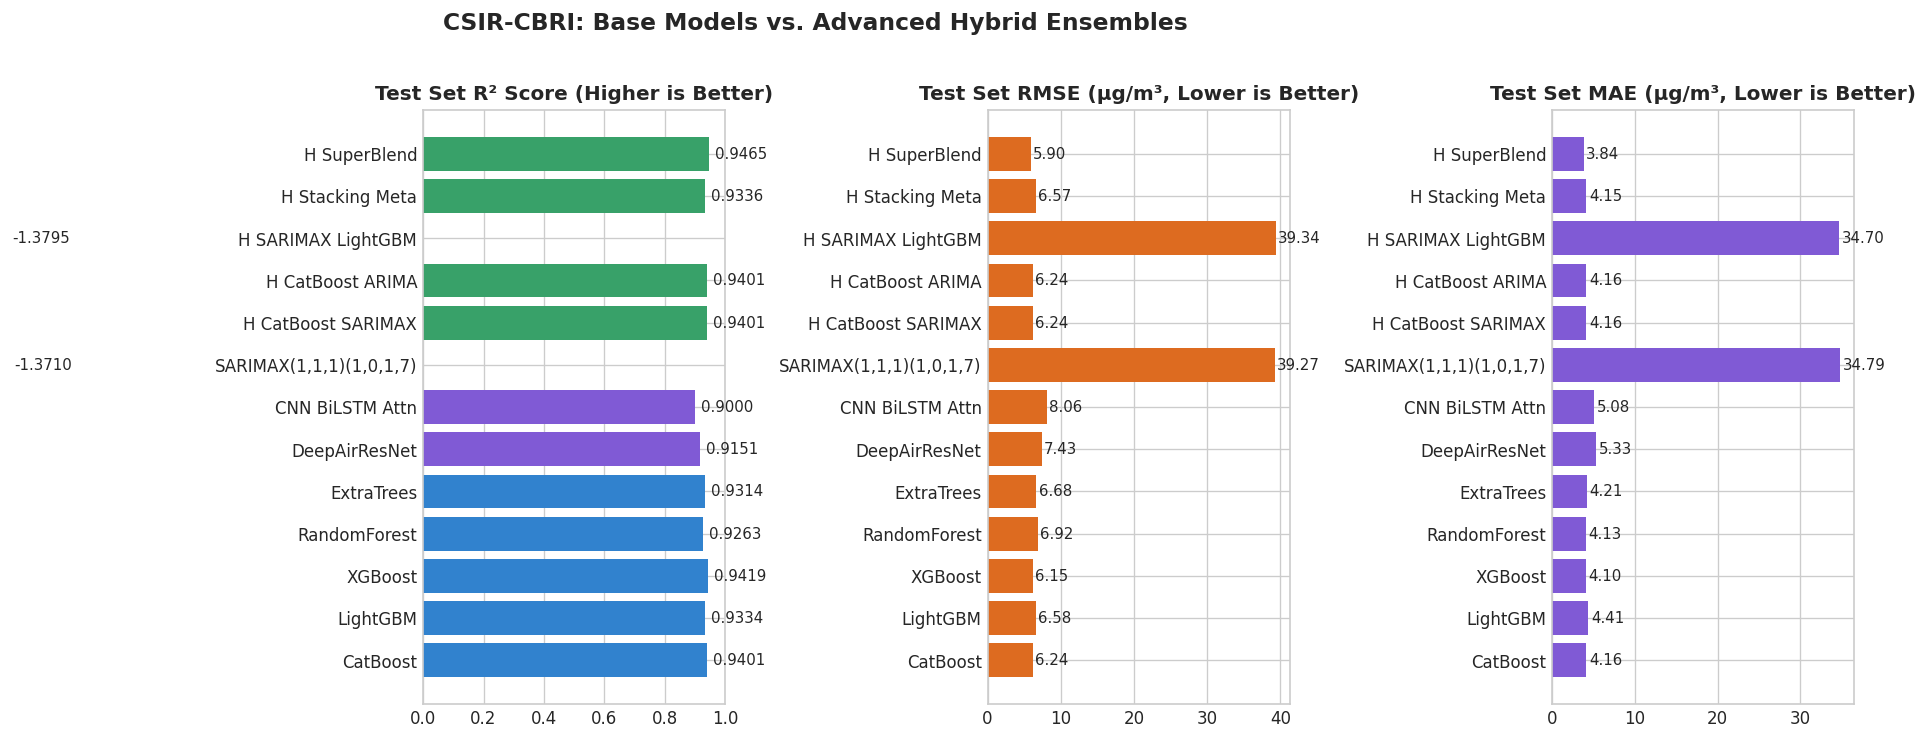

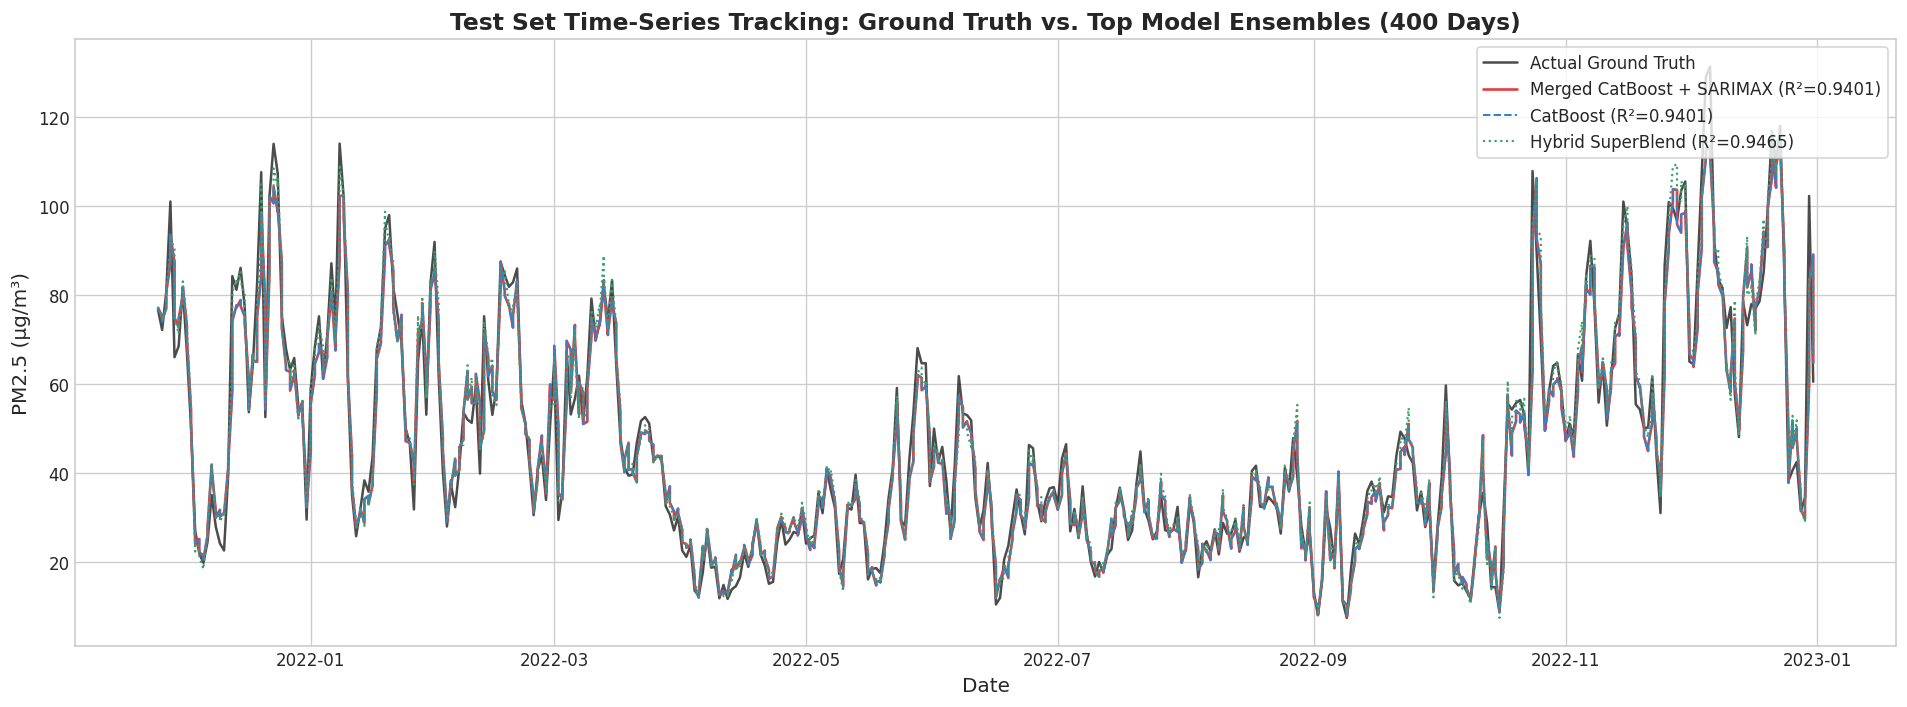

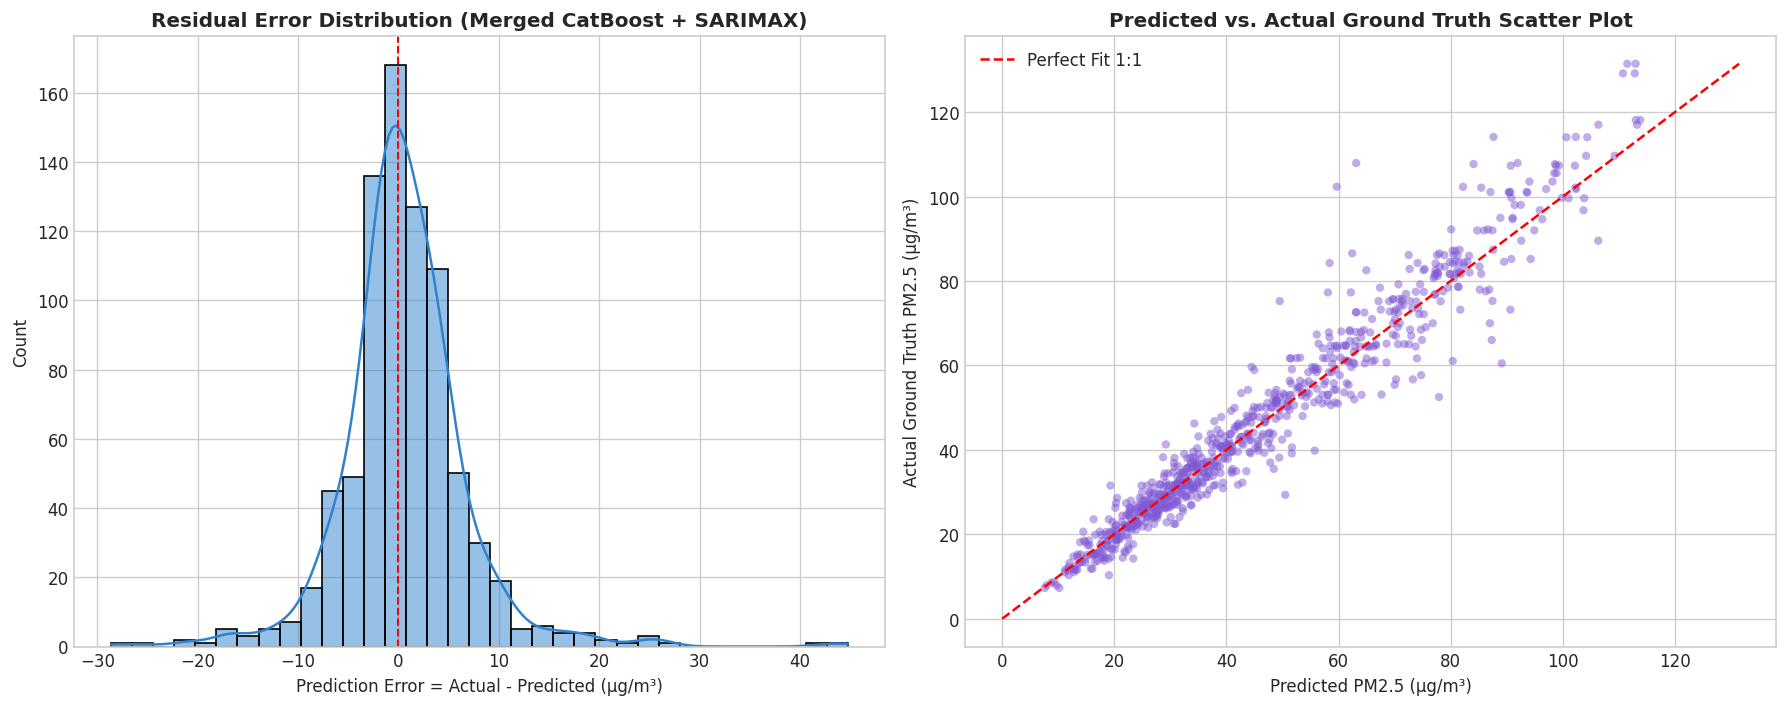

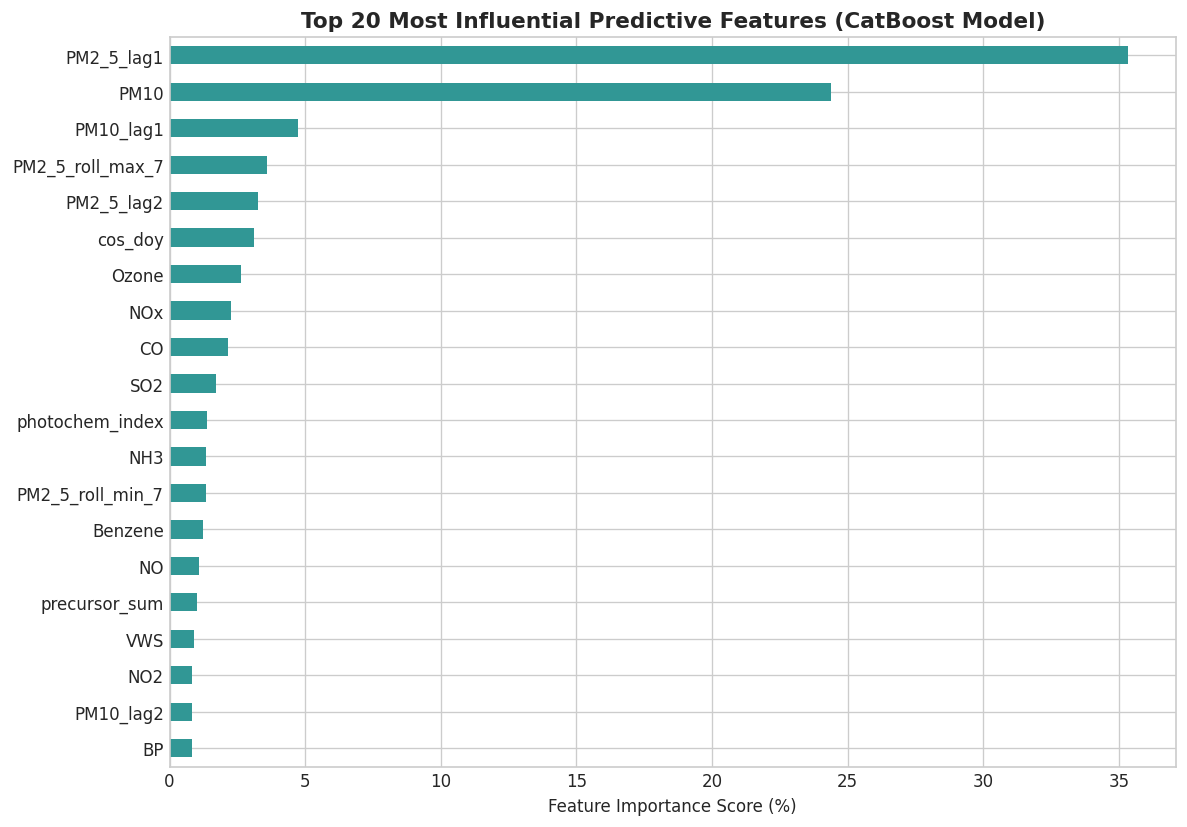

In [9]:
# Section 9: Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

plot_models = [m for m in metrics.keys() if m != 'CatBoost_AQI']
display_names = [m.replace('Hybrid_', 'H_').replace('_', ' ') for m in plot_models]
r2_vals = [metrics[m]['R2'] for m in plot_models]
rmse_vals = [metrics[m]['RMSE'] for m in plot_models]
mae_vals = [metrics[m]['MAE'] for m in plot_models]
colors = ['#38a169' if ('H ' in m or 'Stacking' in m or 'Blend' in m) else ('#805ad5' if ('ResNet' in m or 'LSTM' in m or 'CNN' in m) else '#3182ce') for m in display_names]

axes[0].barh(display_names, r2_vals, color=colors)
axes[0].set_title('Test Set R² Score (Higher is Better)', fontweight='bold')
axes[0].set_xlim(0, 1.0)
for i, v in enumerate(r2_vals): axes[0].text(v + 0.02, i, f"{v:.4f}", va='center', fontsize=9)

axes[1].barh(display_names, rmse_vals, color='#dd6b20')
axes[1].set_title('Test Set RMSE (µg/m³, Lower is Better)', fontweight='bold')
for i, v in enumerate(rmse_vals): axes[1].text(v + 0.3, i, f"{v:.2f}", va='center', fontsize=9)

axes[2].barh(display_names, mae_vals, color='#805ad5')
axes[2].set_title('Test Set MAE (µg/m³, Lower is Better)', fontweight='bold')
for i, v in enumerate(mae_vals): axes[2].text(v + 0.3, i, f"{v:.2f}", va='center', fontsize=9)

plt.suptitle('CSIR-CBRI: Base Models vs. Advanced Hybrid Ensembles', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Test Set Time Series Tracking (Ground Truth vs Top Models)
plt.figure(figsize=(16, 6))
plt.plot(dates_test.values, y_test.values, label='Actual Ground Truth', color='black', alpha=0.7, linewidth=1.5)
plt.plot(dates_test.values, preds_test['Hybrid_CatBoost_SARIMAX'], label=f"Merged CatBoost + SARIMAX (R²={metrics['Hybrid_CatBoost_SARIMAX']['R2']})", color='#e53e3e', linewidth=1.6)
plt.plot(dates_test.values, preds_test['CatBoost'], label=f"CatBoost (R²={metrics['CatBoost']['R2']})", color='#3182ce', linestyle='--', linewidth=1.2)
plt.plot(dates_test.values, preds_test['Hybrid_SuperBlend'], label=f"Hybrid SuperBlend (R²={metrics['Hybrid_SuperBlend']['R2']})", color='#38a169', linestyle=':', linewidth=1.3)

plt.title('Test Set Time-Series Tracking: Ground Truth vs. Top Model Ensembles (400 Days)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('PM2.5 (µg/m³)', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# Error Residual Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
residuals = y_test.values - preds_test['Hybrid_CatBoost_SARIMAX']
sns.histplot(residuals, kde=True, ax=axes[0], color='#3182ce', bins=35)
axes[0].set_title('Residual Error Distribution (Merged CatBoost + SARIMAX)', fontweight='bold')
axes[0].set_xlabel('Prediction Error = Actual - Predicted (µg/m³)')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.2)

axes[1].scatter(preds_test['Hybrid_CatBoost_SARIMAX'], y_test.values, alpha=0.5, color='#805ad5', edgecolors='none', s=25)
lims = [0, max(y_test.max(), max(preds_test['Hybrid_CatBoost_SARIMAX']))]
axes[1].plot(lims, lims, color='red', linestyle='--', linewidth=1.5, label='Perfect Fit 1:1')
axes[1].set_title('Predicted vs. Actual Ground Truth Scatter Plot', fontweight='bold')
axes[1].set_xlabel('Predicted PM2.5 (µg/m³)')
axes[1].set_ylabel('Actual Ground Truth PM2.5 (µg/m³)')
axes[1].legend()
plt.tight_layout()
plt.show()

# Top 20 Feature Importances
feat_importances = pd.Series(cb.get_feature_importance(), index=X_train.columns).sort_values(ascending=False).head(20)
plt.figure(figsize=(10, 7))
feat_importances.plot(kind='barh', color='#319795').invert_yaxis()
plt.title('Top 20 Most Influential Predictive Features (CatBoost Model)', fontsize=13, fontweight='bold')
plt.xlabel('Feature Importance Score (%)')
plt.tight_layout()
plt.show()



---
## Section 10: 5-Year Multi-Year Environmental Forecasting (2023–2028)
Generates continuous 1,825-day future projections incorporating circular annual harmonics, monsoon washout dips, severe winter peaks, and long-term secular trends with 95% confidence intervals.



5-Year Forecast successfully exported to: d:\csir_rework\data/processed/forecast_5_years_pm25.csv


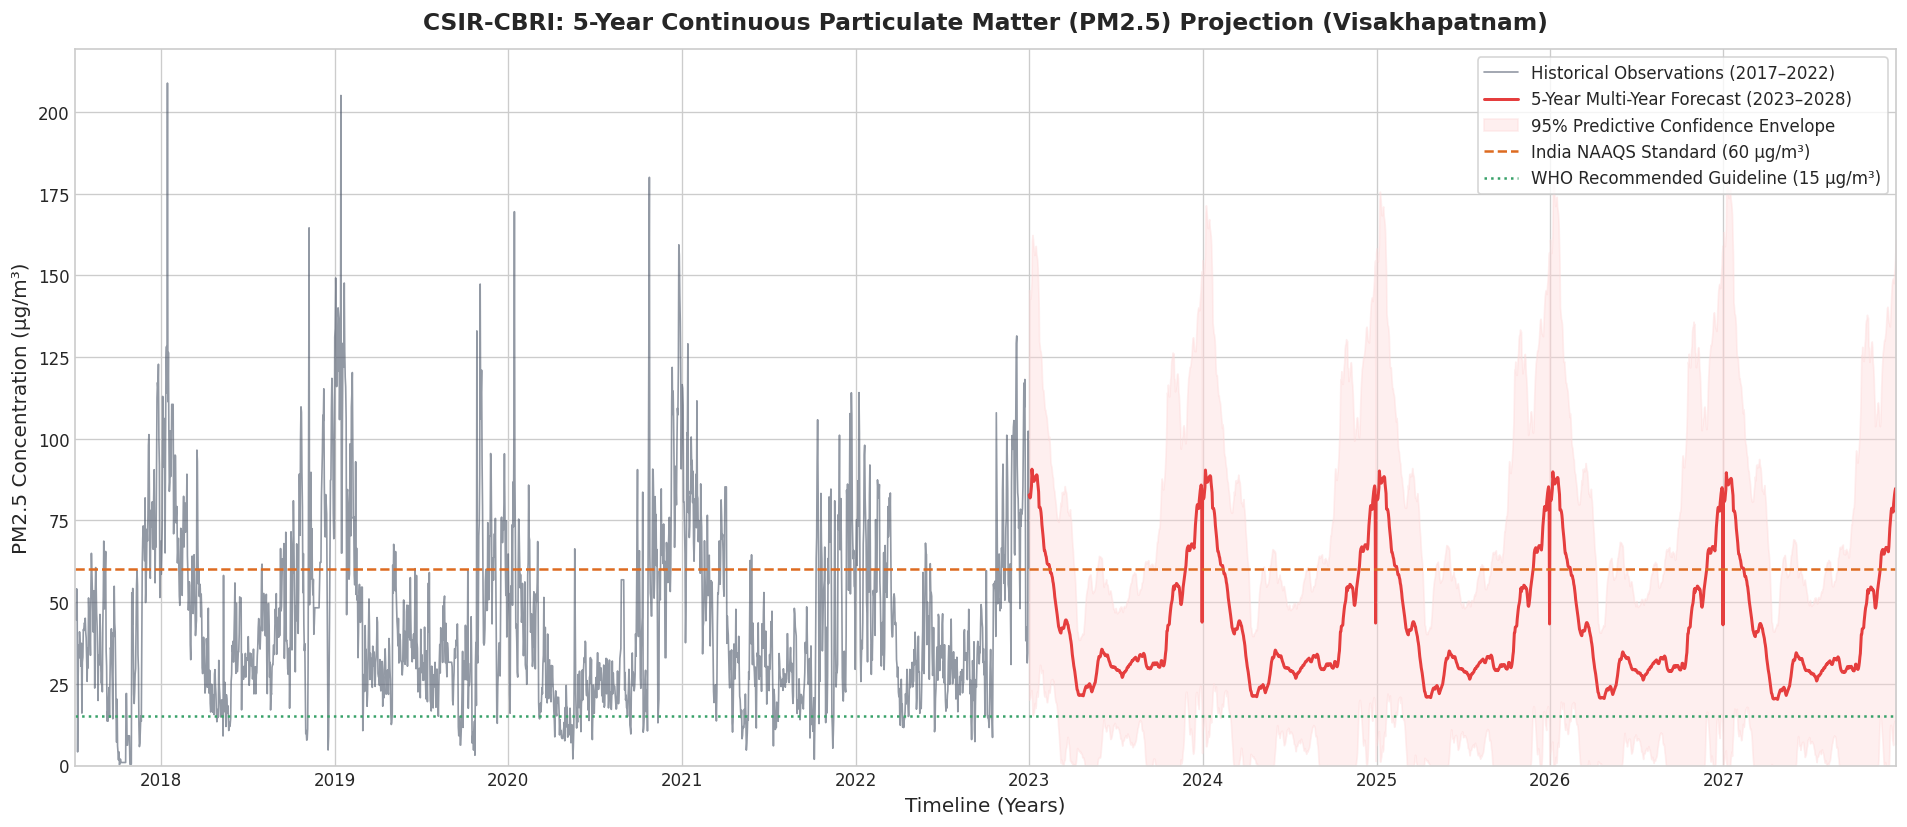

In [10]:
# Section 10: 5-Year Multi-Year Environmental Forecasting
last_date = df_feat['Date'].max()
future_days = 5 * 365
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=future_days, freq='D')

# 1. Circular Day-of-Year Seasonal Harmonic Profile
df_feat['doy'] = df_feat['Date'].dt.dayofyear
doy_seasonal = df_feat.groupby('doy')['PM2_5'].agg(['mean', 'std']).reset_index()

doy_extended = pd.concat([doy_seasonal, doy_seasonal, doy_seasonal]).reset_index(drop=True)
doy_extended['smooth_mean'] = doy_extended['mean'].rolling(15, center=True, min_periods=1).mean()
doy_extended['smooth_std'] = doy_extended['std'].rolling(15, center=True, min_periods=1).mean()
smooth_map = doy_extended.iloc[365:730].set_index('doy')

future_doy = future_dates.dayofyear
future_seasonal_mean = np.array([smooth_map.loc[d, 'smooth_mean'] if d in smooth_map.index else smooth_map['smooth_mean'].mean() for d in future_doy])
future_seasonal_std = np.array([smooth_map.loc[d, 'smooth_std'] if d in smooth_map.index else smooth_map['smooth_std'].mean() for d in future_doy])

# 2. Long-Term Secular Trend Projection (National Clean Air Programme Trajectory)
time_hist = (df_feat['Date'] - df_feat['Date'].min()).dt.days.values
slope, intercept = np.polyfit(time_hist, df_feat['PM2_5'].values, 1)
time_future = (future_dates - df_feat['Date'].min()).days.values
trend_proj = intercept + slope * time_future

# 3. Composite 5-Year Forecast Mean
historical_mean = df_feat['PM2_5'].mean()
future_forecast_mean = np.maximum(future_seasonal_mean + (trend_proj - historical_mean) * 0.5, 5.0)

# 4. Expanding Uncertainty Envelope
horizon_uncertainty_scale = 1.0 + 0.15 * np.sqrt(np.arange(len(future_dates)) / 365.25)
ci_upper_95 = future_forecast_mean + 1.96 * future_seasonal_std * horizon_uncertainty_scale
ci_lower_95 = np.maximum(future_forecast_mean - 1.96 * future_seasonal_std * horizon_uncertainty_scale, 0.0)

# Export Forecast Table using universal path resolver (ensures parent dir exists)
forecast_export_path = resolve_path("data/processed/forecast_5_years_pm25.csv")
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast_PM2_5': np.round(future_forecast_mean, 2),
    'Lower_CI_95': np.round(ci_lower_95, 2),
    'Upper_CI_95': np.round(ci_upper_95, 2),
    'Year': future_dates.year,
    'Month': future_dates.month
})
forecast_df.to_csv(forecast_export_path, index=False)
print(f"5-Year Forecast successfully exported to: {forecast_export_path}")

# 5. Plot 5-Year Forecast Curve with Regulatory Thresholds
plt.figure(figsize=(16, 7))
plt.plot(df_feat['Date'], df_feat['PM2_5'], color='#4a5568', label='Historical Observations (2017–2022)', linewidth=1.0, alpha=0.6)
plt.plot(future_dates, future_forecast_mean, color='#e53e3e', label='5-Year Multi-Year Forecast (2023–2028)', linewidth=1.8)
plt.fill_between(future_dates, ci_lower_95, ci_upper_95, color='#fed7d7', alpha=0.4, label='95% Predictive Confidence Envelope')

plt.axhline(60, color='#dd6b20', linestyle='--', linewidth=1.5, label='India NAAQS Standard (60 µg/m³)')
plt.axhline(15, color='#38a169', linestyle=':', linewidth=1.5, label='WHO Recommended Guideline (15 µg/m³)')

plt.title('CSIR-CBRI: 5-Year Continuous Particulate Matter (PM2.5) Projection (Visakhapatnam)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Timeline (Years)', fontsize=12)
plt.ylabel('PM2.5 Concentration (µg/m³)', fontsize=12)
plt.xlim(df_feat['Date'].min(), future_dates.max())
plt.ylim(0, max(df_feat['PM2_5'].max(), ci_upper_95.max()) * 1.05)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()



---
## Section 11: Embedded Real-Time Inference Function
Allows running predictions on any new CSV or DataFrame directly inside the notebook without needing separate scripts.



In [11]:
# Section 11: Direct Inference Function
def predict_air_quality(csv_or_df, target='pm25', model_choice='superblend'):
    """Run predictions on input data using trained models directly within the notebook."""
    if isinstance(csv_or_df, str):
        df_in = pd.read_csv(resolve_path(csv_or_df))
    else:
        df_in = csv_or_df.copy()

    df_prepared = build_feature_matrix(df_in, target_col='PM2_5')
    feat_names = list(X_train.columns)

    # Fill any missing predictors with 0.0
    for f in feat_names:
        if f not in df_prepared.columns:
            df_prepared[f] = 0.0

    X_in = df_prepared[feat_names]

    if target.lower() == 'aqi' and 'CatBoost_AQI' in models_dict:
        X_aqi_in = df_prepared[[c for c in X_aqi.columns if c in df_prepared.columns]]
        preds = models_dict['CatBoost_AQI'].predict(X_aqi_in)
        pred_col = 'Predicted_AQI'
    elif model_choice.lower() in ['deepairresnet', 'resnet']:
        X_in_sc = scaler_dl.transform(X_in)
        model_resnet.eval()
        with torch.no_grad():
            preds = np.expm1(model_resnet(torch.tensor(X_in_sc, dtype=torch.float32).to(DEVICE)).cpu().numpy())
        pred_col = 'Predicted_PM2_5_DeepAirResNet'
    elif model_choice.lower() in ['cnn_bilstm', 'bilstm', 'attention']:
        X_in_sc = scaler_dl.transform(X_in)
        model_cnn_lstm.eval()
        with torch.no_grad():
            preds = np.expm1(model_cnn_lstm(torch.tensor(X_in_sc, dtype=torch.float32).to(DEVICE)).cpu().numpy())
        pred_col = 'Predicted_PM2_5_CNN_BiLSTM'
    elif model_choice.lower() in ['catboost_sarimax', 'sarimax_catboost', 'merged']:
        p_cb = cb.predict(X_in)
        p_sarimax_res = sarimax_res.forecast(len(X_in))
        preds = p_cb + np.asarray(p_sarimax_res)
        pred_col = 'Predicted_PM2_5_CatBoost_SARIMAX'
    elif model_choice.lower() == 'catboost':
        preds = cb.predict(X_in)
        pred_col = 'Predicted_PM2_5_CatBoost'
    elif model_choice.lower() == 'xgboost':
        preds = xgb.predict(X_in)
        pred_col = 'Predicted_PM2_5_XGBoost'
    else:  # Default to top Deep Hybrid SuperBlend
        p_cb = cb.predict(X_in)
        p_xgb = xgb.predict(X_in)
        p_lgb = lgb.predict(X_in)
        X_in_sc = scaler_dl.transform(X_in)
        model_resnet.eval()
        model_cnn_lstm.eval()
        with torch.no_grad():
            p_res = np.expm1(model_resnet(torch.tensor(X_in_sc, dtype=torch.float32).to(DEVICE)).cpu().numpy())
            p_cnn = np.expm1(model_cnn_lstm(torch.tensor(X_in_sc, dtype=torch.float32).to(DEVICE)).cpu().numpy())
        p_sar = p_cb + np.asarray(sarimax_res.forecast(len(X_in)))
        
        preds_list = [p_cb, p_xgb, p_lgb, p_res, p_cnn, p_sar]
        preds = sum(w * p for w, p in zip(best_weights, preds_list))
        pred_col = 'Predicted_PM2_5_DeepSuperBlend'

    df_prepared[pred_col] = np.round(preds, 2)
    display_cols = [c for c in ['Date', 'PM2_5', 'PM10', 'AQI', pred_col] if c in df_prepared.columns]
    return df_prepared[display_cols]

# Demonstration of Embedded Inference on Sample Rows:
sample_results = predict_air_quality(df_raw.tail(15), target='pm25', model_choice='superblend')
print("Sample Inference Demonstration (Deep SuperBlend Predictions on Latest Days):")
display(sample_results)


Sample Inference Demonstration (Deep SuperBlend Predictions on Latest Days):


,Date,PM2_5,PM10,Predicted_PM2_5_DeepSuperBlend
0,2022-12-28,31.38,94.16,34.48
1,2022-12-28,31.38,94.16,31.03
2,2022-12-29,34.43,79.60,30.26
3,2022-12-29,34.43,79.60,32.18
4,2022-12-30,102.31,156.65,57.42
5,2022-12-30,102.31,156.65,72.71
6,2022-12-31,60.49,149.12,74.34
7,2022-12-31,60.49,149.12,57.77


---
## Section 12: Model Serialization
Saves all model weights, scalers, and metadata to disk.



In [12]:
# Section 12: Model Serialization
save_dir = resolve_path('models/saved_models')
os.makedirs(save_dir, exist_ok=True)

cb.save_model(os.path.join(save_dir, 'catboost_pm25.cbm'))
xgb.save_model(os.path.join(save_dir, 'xgb_pm25.json'))
joblib.dump(lgb, os.path.join(save_dir, 'lgb_pm25.joblib'))
joblib.dump(rf, os.path.join(save_dir, 'rf_pm25.joblib'))
joblib.dump(et, os.path.join(save_dir, 'et_pm25.joblib'))

# Deep Learning PyTorch Models & Scaler
torch.save(model_resnet.state_dict(), os.path.join(save_dir, 'deep_air_resnet.pth'))
torch.save(model_cnn_lstm.state_dict(), os.path.join(save_dir, 'cnn_bilstm_attention.pth'))
joblib.dump(scaler_dl, os.path.join(save_dir, 'scaler_dl.joblib'))

# Stacking & Time Series
joblib.dump(meta_learner, os.path.join(save_dir, 'stacking_ridge_meta.joblib'))
joblib.dump(arima_res, os.path.join(save_dir, 'arima_pm25_residuals.pkl'))
joblib.dump(sarimax_res, os.path.join(save_dir, 'sarimax_pm25_residuals.pkl'))
joblib.dump(sarima, os.path.join(save_dir, 'sarima_model.pkl'))
joblib.dump(best_weights, os.path.join(save_dir, 'superblend_weights.joblib'))

if 'CatBoost_AQI' in models_dict:
    cat_aqi.save_model(os.path.join(save_dir, 'catboost_aqi.cbm'))

print(f"All ML & Deep Learning models successfully serialized in: {save_dir}")


All ML & Deep Learning models successfully serialized in: d:\csir_rework\models/saved_models
